# Explainable Road Damage Detection Using Transfer Learning + Grad-CAM

### Project Pipeline

YOLO/Polygon Annotations
        ↓
Extract Object Bounding Boxes
        ↓
Create Damage Crops
        ↓
Train / Validation / Test Split
        ↓
MobileNetV2 Transfer Learning
        ↓
Road Damage Classification
        ↓
Grad-CAM Explanation
        ↓
Prediction + Confidence + Heatmap

### Classes
- Pothole
- Crack
- Manhole

The original dataset is designed for object detection.
For this project, the annotated damage regions are converted into
individual image crops so that we can train an image classifier.

In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import glob
import random
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.20.0
GPU available: []


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes")

print("Path to dataset files:", path)

# ============================================================
# 2. FIND DATASET DIRECTORIES
# ============================================================

#KAGGLE_INPUT = "/kaggle/input"
KAGGLE_INPUT = path

# Search recursively for folders called "images" and "labels"
image_dirs = []
label_dirs = []

for root, dirs, files in os.walk(KAGGLE_INPUT):
    for d in dirs:
        if d.lower() == "images":
            image_dirs.append(os.path.join(root, d))
        elif d.lower() in ["labels", "labels-yolo"]:
            label_dirs.append(os.path.join(root, d))

print("Image directories found:")
for d in image_dirs:
    print(" ", d)

print("\nLabel directories found:")
for d in label_dirs:
    print(" ", d)

Using Colab cache for faster access to the 'road-damage-dataset-potholes-cracks-and-manholes' dataset.
Path to dataset files: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes
Image directories found:
  /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/images

Label directories found:
  /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/labels
  /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/labels-YOLO


In [ ]:
# ============================================================
# 3. SELECT IMAGE + LABEL DIRECTORIES
# ============================================================

if not image_dirs:
    raise FileNotFoundError("Could not find the dataset's images folder.")

if not label_dirs:
    raise FileNotFoundError("Could not find the dataset's labels folder.")

IMAGE_DIR = image_dirs[0]
LABEL_DIR = label_dirs[0]

print("IMAGE_DIR:", IMAGE_DIR)
print("LABEL_DIR:", LABEL_DIR)

IMAGE_DIR: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/images
LABEL_DIR: /kaggle/input/road-damage-dataset-potholes-cracks-and-manholes/data/labels


In [ ]:
# ============================================================
# 4. COUNT IMAGES AND LABEL FILES
# ============================================================

image_files = []

for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
    image_files.extend(glob.glob(os.path.join(IMAGE_DIR, ext)))

label_files = glob.glob(os.path.join(LABEL_DIR, "*.txt"))

print(f"Number of images: {len(image_files):,}")
print(f"Number of label files: {len(label_files):,}")

Number of images: 2,009
Number of label files: 2,009


In [ ]:
# ============================================================
# 5. CLASS DEFINITIONS
# ============================================================

CLASS_NAMES = {
    0: "Pothole",
    1: "Crack",
    2: "Manhole"
}

NUM_CLASSES = len(CLASS_NAMES)

print(CLASS_NAMES)

{0: 'Pothole', 1: 'Crack', 2: 'Manhole'}


In [ ]:
# ============================================================
# 6. PARSE YOLO POLYGON ANNOTATIONS
# ============================================================

def parse_label_file(label_path):
    """
    Reads one YOLO polygon annotation file.

    Expected format:
        class_id x1 y1 x2 y2 x3 y3 x4 y4

    Coordinates are normalized between 0 and 1.
    """

    annotations = []

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = line.strip().split()

        if len(values) < 9:
            continue

        class_id = int(values[0])
        coords = list(map(float, values[1:]))

        # Convert flat coordinate list into (x, y) pairs
        polygon = np.array(coords).reshape(-1, 2)

        annotations.append({
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "polygon": polygon
        })

    return annotations

In [ ]:
# ============================================================
# 7. BUILD ANNOTATION DATAFRAME
# ============================================================

records = []

for label_path in label_files:

    label_name = Path(label_path).stem

    # Find matching image
    matching_images = []

    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
        candidate = os.path.join(IMAGE_DIR, label_name + ext)

        if os.path.exists(candidate):
            matching_images.append(candidate)

    if not matching_images:
        continue

    image_path = matching_images[0]

    annotations = parse_label_file(label_path)

    for ann in annotations:

        records.append({
            "image_path": image_path,
            "label_path": label_path,
            "class_id": ann["class_id"],
            "class_name": ann["class_name"],
            "polygon": ann["polygon"]
        })

annotations_df = pd.DataFrame(records)

print("Total annotated objects:", len(annotations_df))
annotations_df.head()

Total annotated objects: 4737


,image_path,label_path,class_id,class_name,polygon
0,/kaggle/input/road-damage-dataset-potholes-cra...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole,"[[0.342187, 0.558333], [0.403125, 0.558333], [..."
1,/kaggle/input/road-damage-dataset-potholes-cra...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole,"[[0.409375, 0.561111], [0.453125, 0.561111], [..."
2,/kaggle/input/road-damage-dataset-potholes-cra...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole,"[[0.2625, 0.627778], [0.35625, 0.627778], [0.3..."
3,/kaggle/input/road-damage-dataset-potholes-cra...,/kaggle/input/road-damage-dataset-potholes-cra...,1,Crack,"[[0.282813, 0.672222], [0.365625, 0.672222], [..."
4,/kaggle/input/road-damage-dataset-potholes-cra...,/kaggle/input/road-damage-dataset-potholes-cra...,0,Pothole,"[[0.396875, 0.719444], [0.532813, 0.719444], [..."


class_name
Pothole    1261
Crack      2519
Manhole     957
Name: count, dtype: int64


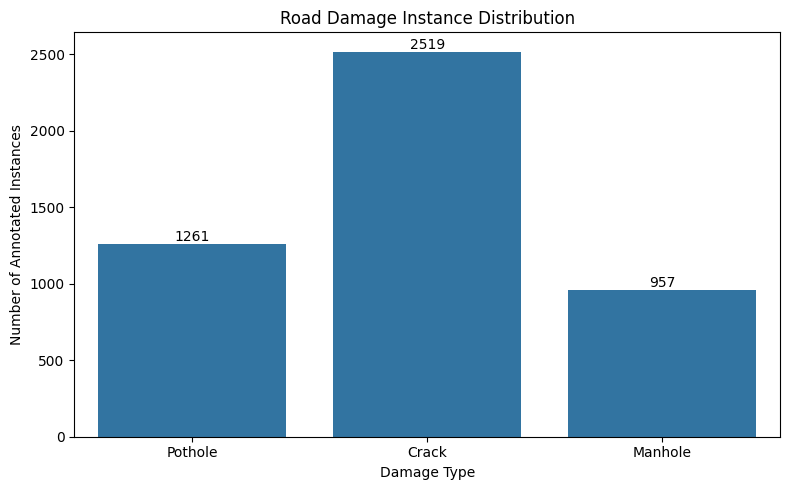

In [ ]:
# ============================================================
# 8. CLASS DISTRIBUTION
# ============================================================

class_counts = (
    annotations_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES.values())
)

print(class_counts)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Road Damage Instance Distribution")
plt.xlabel("Damage Type")
plt.ylabel("Number of Annotated Instances")

# Add values above bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

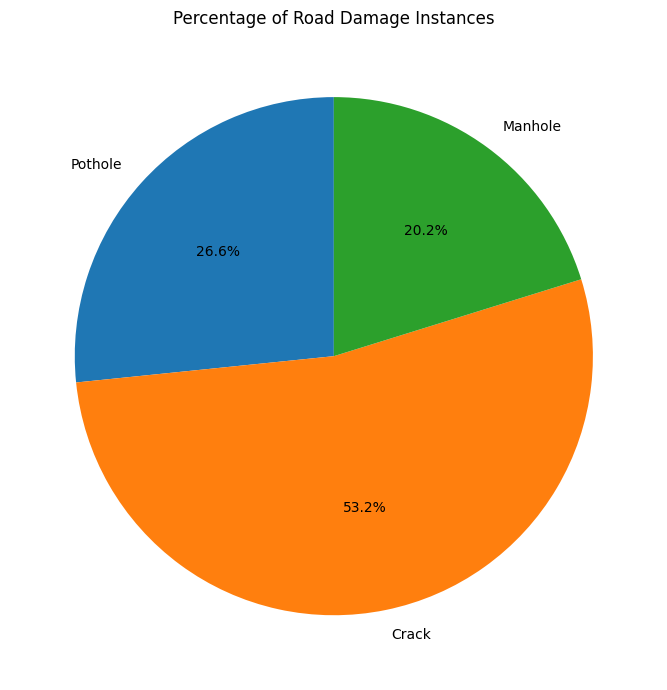

In [ ]:
# ============================================================
# 9. CLASS PERCENTAGES
# ============================================================

class_percentage = (
    class_counts / class_counts.sum() * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percentage.values,
    labels=class_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Road Damage Instances")

plt.tight_layout()
plt.show()

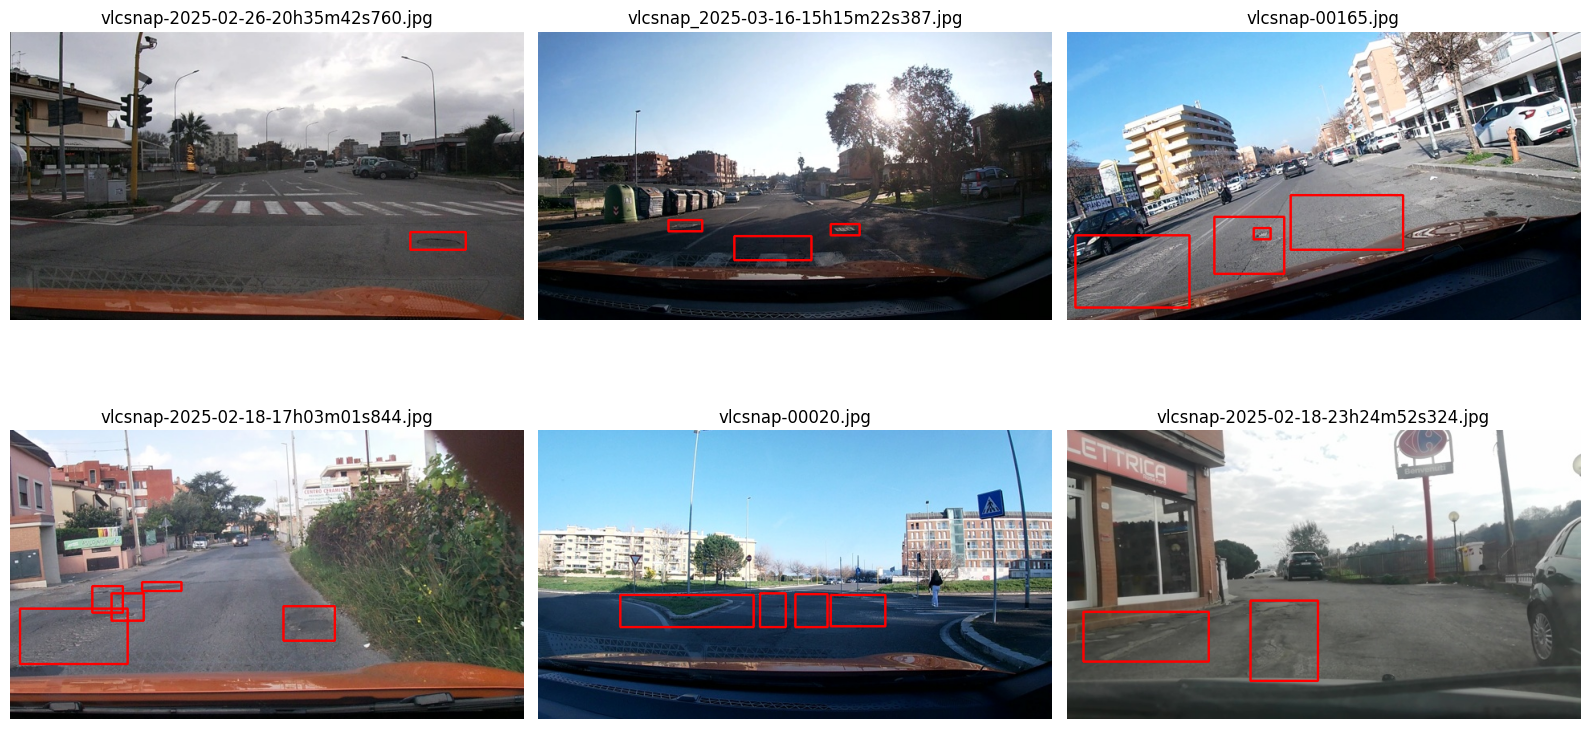

In [ ]:
# ============================================================
# 10. VISUALIZE ANNOTATED IMAGES
# ============================================================

def draw_annotations(image_path, annotations):
    """
    Draw polygon annotations on an image.
    """

    image = cv2.imread(image_path)

    if image is None:
        return None

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    output = image.copy()

    for ann in annotations:

        polygon = ann["polygon"].copy()

        # Convert normalized coordinates → pixel coordinates
        polygon[:, 0] *= w
        polygon[:, 1] *= h

        polygon = polygon.astype(np.int32)

        cv2.polylines(
            output,
            [polygon],
            isClosed=True,
            color=(255, 0, 0),
            thickness=2
        )

    return output


# Select a few random images
sample_images = random.sample(
    list(annotations_df["image_path"].unique()),
    min(6, annotations_df["image_path"].nunique())
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):

    image_annotations = annotations_df[
        annotations_df["image_path"] == image_path
    ].to_dict("records")

    image = draw_annotations(image_path, image_annotations)

    ax.imshow(image)
    ax.set_title(Path(image_path).name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 11. EXTRACT OBJECT CROPS
# ============================================================

CROP_DIR = "/kaggle/working/road_damage_crops"

if os.path.exists(CROP_DIR):
    shutil.rmtree(CROP_DIR)

os.makedirs(CROP_DIR, exist_ok=True)

for class_name in CLASS_NAMES.values():
    os.makedirs(
        os.path.join(CROP_DIR, class_name),
        exist_ok=True
    )


def polygon_to_bbox(polygon, image_width, image_height, padding=0.10):
    """
    Convert normalized polygon coordinates
    into a padded pixel bounding box.
    """

    x_coords = polygon[:, 0] * image_width
    y_coords = polygon[:, 1] * image_height

    x_min = int(np.min(x_coords))
    x_max = int(np.max(x_coords))
    y_min = int(np.min(y_coords))
    y_max = int(np.max(y_coords))

    # Add some context around the damage
    width = x_max - x_min
    height = y_max - y_min

    pad_x = int(width * padding)
    pad_y = int(height * padding)

    x_min = max(0, x_min - pad_x)
    y_min = max(0, y_min - pad_y)

    x_max = min(image_width, x_max + pad_x)
    y_max = min(image_height, y_max + pad_y)

    return x_min, y_min, x_max, y_max


crop_records = []

for idx, row in annotations_df.iterrows():

    image = cv2.imread(row["image_path"])

    if image is None:
        continue

    h, w = image.shape[:2]

    x_min, y_min, x_max, y_max = polygon_to_bbox(
        row["polygon"],
        w,
        h,
        padding=0.15
    )

    crop = image[y_min:y_max, x_min:x_max]

    if crop.size == 0:
        continue

    class_name = row["class_name"]

    output_name = (
        f"{Path(row['image_path']).stem}"
        f"_obj_{idx}.jpg"
    )

    output_path = os.path.join(
        CROP_DIR,
        class_name,
        output_name
    )

    cv2.imwrite(output_path, crop)

    crop_records.append({
        "crop_path": output_path,
        "original_image": row["image_path"],
        "class_id": row["class_id"],
        "class_name": class_name
    })


crops_df = pd.DataFrame(crop_records)

print("Generated crops:", len(crops_df))
crops_df.head()

Generated crops: 4736


,crop_path,original_image,class_id,class_name
0,/kaggle/working/road_damage_crops/Manhole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole
1,/kaggle/working/road_damage_crops/Manhole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole
2,/kaggle/working/road_damage_crops/Manhole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole
3,/kaggle/working/road_damage_crops/Crack/vlcsna...,/kaggle/input/road-damage-dataset-potholes-cra...,1,Crack
4,/kaggle/working/road_damage_crops/Pothole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,0,Pothole


class_name
Pothole    1261
Crack      2518
Manhole     957
Name: count, dtype: int64


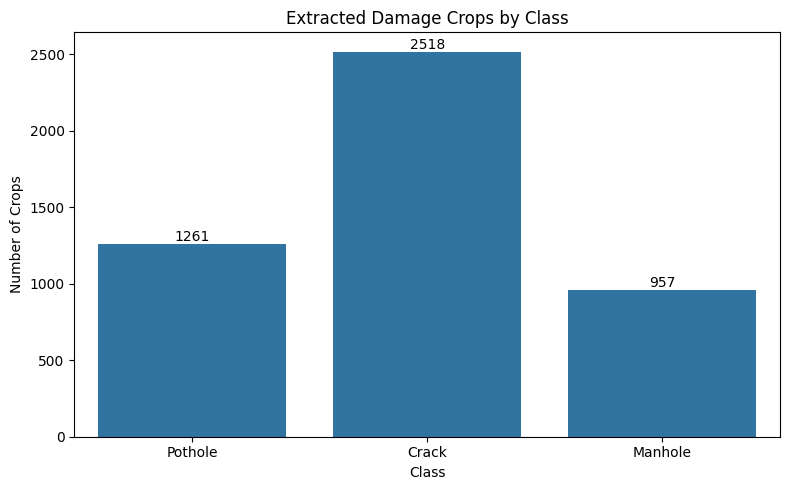

In [ ]:
# ============================================================
# 12. CROP DISTRIBUTION
# ============================================================

crop_counts = (
    crops_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES.values())
)

print(crop_counts)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=crop_counts.index,
    y=crop_counts.values
)

plt.title("Extracted Damage Crops by Class")
plt.xlabel("Class")
plt.ylabel("Number of Crops")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

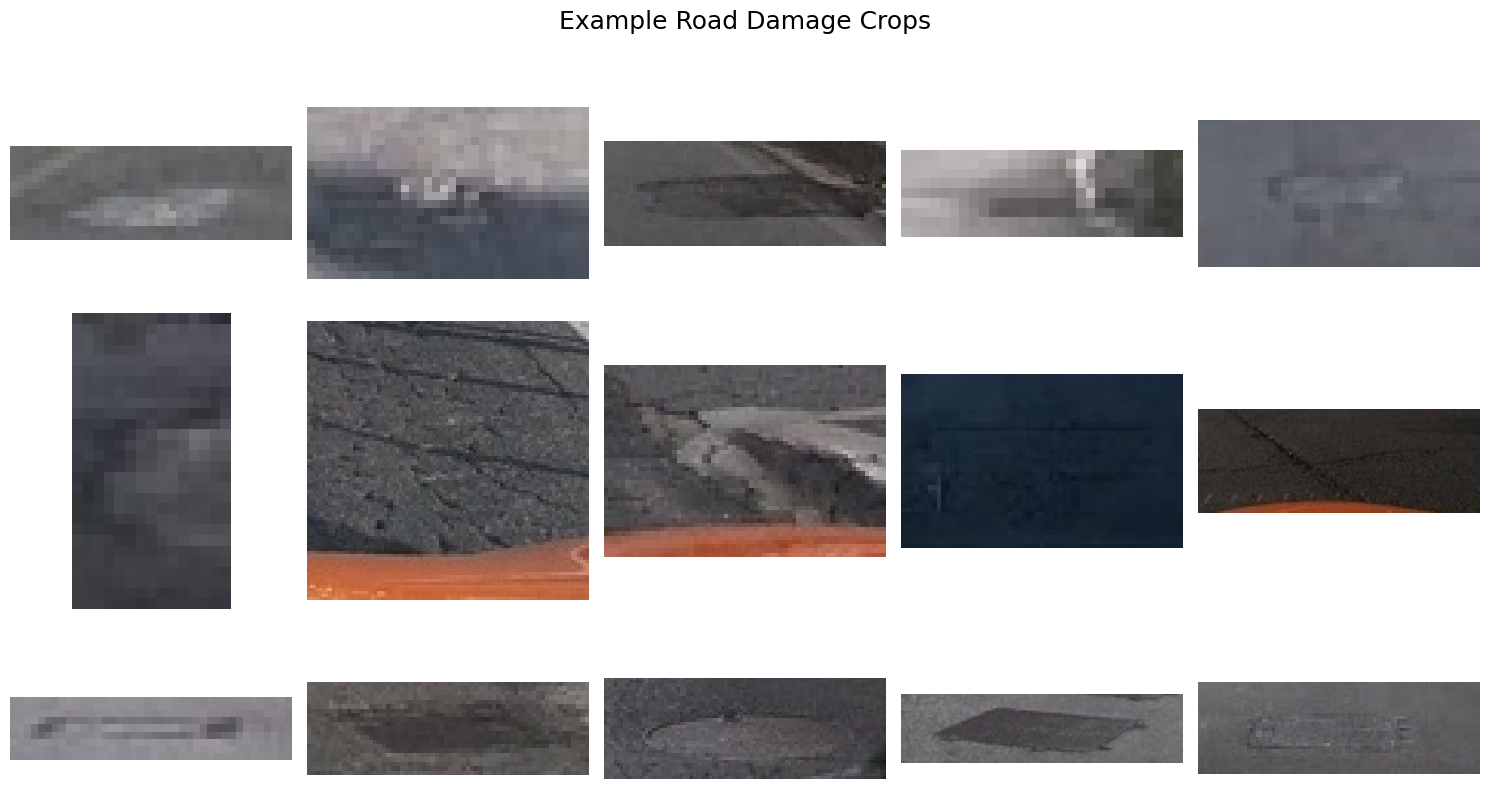

In [ ]:
# ============================================================
# 13. SHOW SAMPLE CROPS
# ============================================================

fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 9)
)

for row_idx, class_name in enumerate(CLASS_NAMES.values()):

    samples = crops_df[
        crops_df["class_name"] == class_name
    ].sample(
        min(5, len(crops_df[crops_df["class_name"] == class_name])),
        random_state=SEED
    )

    for col_idx, (_, row) in enumerate(samples.iterrows()):

        image = cv2.imread(row["crop_path"])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        axes[row_idx, col_idx].imshow(image)
        axes[row_idx, col_idx].axis("off")

        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(
                class_name,
                fontsize=14
            )

plt.suptitle(
    "Example Road Damage Crops",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 14. IMAGE-LEVEL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

unique_images = crops_df[
    ["original_image", "class_name"]
].drop_duplicates()

# Stratification is based on the class represented by the image.
# For images containing multiple classes, the first encountered
# class is used for stratification only.

stratify_labels = (
    unique_images
    .groupby("original_image")["class_name"]
    .first()
)

image_paths = stratify_labels.index.values
image_labels = stratify_labels.values

train_images, temp_images, _, temp_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

val_images, test_images = train_test_split(
    temp_images,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

train_images = set(train_images)
val_images = set(val_images)
test_images = set(test_images)

train_df = crops_df[
    crops_df["original_image"].isin(train_images)
].copy()

val_df = crops_df[
    crops_df["original_image"].isin(val_images)
].copy()

test_df = crops_df[
    crops_df["original_image"].isin(test_images)
].copy()

print("Train crops:", len(train_df))
print("Validation crops:", len(val_df))
print("Test crops:", len(test_df))

print("\nUnique source images:")
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Train crops: 3303
Validation crops: 741
Test crops: 692

Unique source images:
Train: 1406
Validation: 301
Test: 302


In [ ]:
# ============================================================
# 15. ENCODE CLASS LABELS
# ============================================================

class_to_index = {
    "Pothole": 0,
    "Crack": 1,
    "Manhole": 2
}

index_to_class = {
    v: k for k, v in class_to_index.items()
}

def encode_dataframe(df):

    df = df.copy()

    df["label"] = df["class_name"].map(class_to_index)

    return df


train_df = encode_dataframe(train_df)
val_df = encode_dataframe(val_df)
test_df = encode_dataframe(test_df)

train_df.head()

,crop_path,original_image,class_id,class_name,label
2,/kaggle/working/road_damage_crops/Manhole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,2,Manhole,2
3,/kaggle/working/road_damage_crops/Crack/vlcsna...,/kaggle/input/road-damage-dataset-potholes-cra...,1,Crack,1
4,/kaggle/working/road_damage_crops/Pothole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,0,Pothole,0
5,/kaggle/working/road_damage_crops/Pothole/vlcs...,/kaggle/input/road-damage-dataset-potholes-cra...,0,Pothole,0
6,/kaggle/working/road_damage_crops/Crack/vlcsna...,/kaggle/input/road-damage-dataset-potholes-cra...,1,Crack,1


In [ ]:
# ============================================================
# 16. TF.DATA PIPELINE
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32


def load_image(path, label):
    """
    Load an image and prepare it for MobileNetV2.
    """

    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = preprocess_input(image)

    return image, label


def create_dataset(df, shuffle=False):

    paths = df["crop_path"].values
    labels = df["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(
    train_df,
    shuffle=True
)

val_ds = create_dataset(
    val_df
)

test_ds = create_dataset(
    test_df
)

In [ ]:
# ============================================================
# 17. DATA AUGMENTATION
# ============================================================

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

In [ ]:
# ============================================================
# 18. BUILD TRANSFER LEARNING MODEL
# ============================================================

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Initially freeze the pretrained backbone
base_model.trainable = False


inputs = keras.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(
    0.30,
    name="dropout"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="predictions"
)(x)


model = keras.Model(
    inputs,
    outputs,
    name="RoadDamage_MobileNetV2"
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "RoadDamage_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# ============================================================
# 19. COMPILE MODEL
# ============================================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
# ============================================================
# 20. TRAIN CLASSIFICATION HEAD
# ============================================================

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]


history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.5123 - loss: 1.0441 - val_accuracy: 0.6437 - val_loss: 0.7938 - learning_rate: 0.0010
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.5640 - loss: 0.9095 - val_accuracy: 0.6370 - val_loss: 0.8244 - learning_rate: 0.0010
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.5771 - loss: 0.8652 - val_accuracy: 0.6248 - val_loss: 0.9264 - learning_rate: 0.0010
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.5943 - loss: 0.8510 - val_accuracy: 0.6775 - val_loss: 0.7122 - learning_rate: 2.0000e-04
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.6119 - loss: 0.8217 - val_accuracy: 0.6788 - val_loss: 0.7555 - learning_rate: 2.0000e-04
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.5949 - loss: 0.8218 - val_accuracy: 0.6640 - val_loss: 0.7313 - learning_rate: 2.0000e-04
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.611

In [ ]:
# ============================================================
# 21. FINE-TUNE UPPER MOBILENETV2 LAYERS
# ============================================================

base_model.trainable = True

# Freeze most layers and only fine-tune the upper portion
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False


model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.5540 - loss: 0.9470 - val_accuracy: 0.6748 - val_loss: 0.7047 - learning_rate: 1.0000e-05
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 190s 2s/step - accuracy: 0.5749 - loss: 0.8895 - val_accuracy: 0.6964 - val_loss: 0.6936 - learning_rate: 1.0000e-05
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - accuracy: 0.5889 - loss: 0.8535 - val_accuracy: 0.6950 - val_loss: 0.6919 - learning_rate: 1.0000e-05
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 176s 2s/step - accuracy: 0.5861 - loss: 0.8451 - val_accuracy: 0.6964 - val_loss: 0.6855 - learning_rate: 1.0000e-05
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 198s 2s/step - accuracy: 0.6016 - loss: 0.8143 - val_accuracy: 0.7018 - val_loss: 0.6760 - learning_rate: 1.0000e-05
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 173s 2s/step - accuracy: 0.6043 - loss: 0.8121 - val_accuracy: 0.7018 - val_loss: 0.6877 - learning_rate: 1.0000e-05
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 170s 2s/step - acc

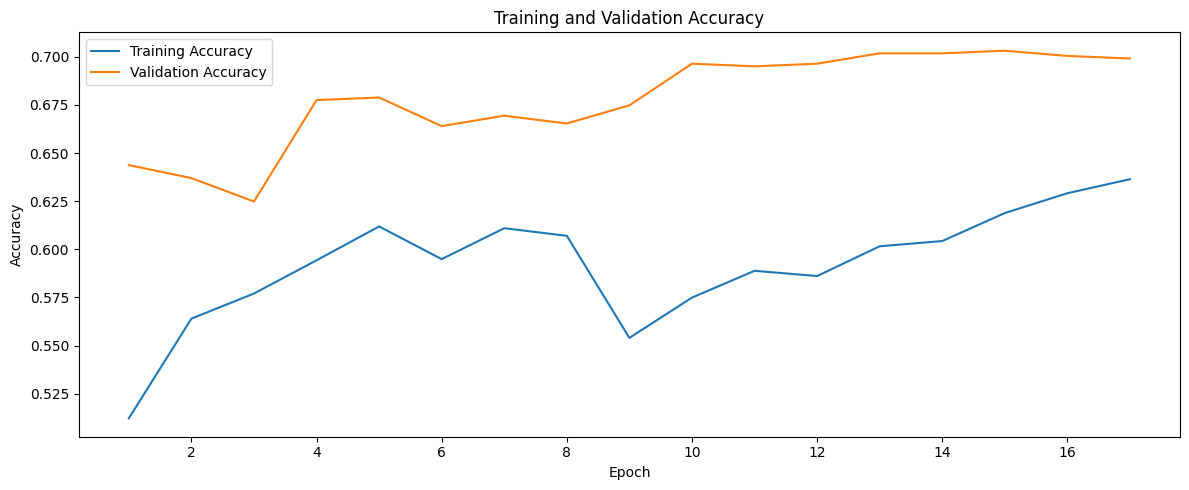

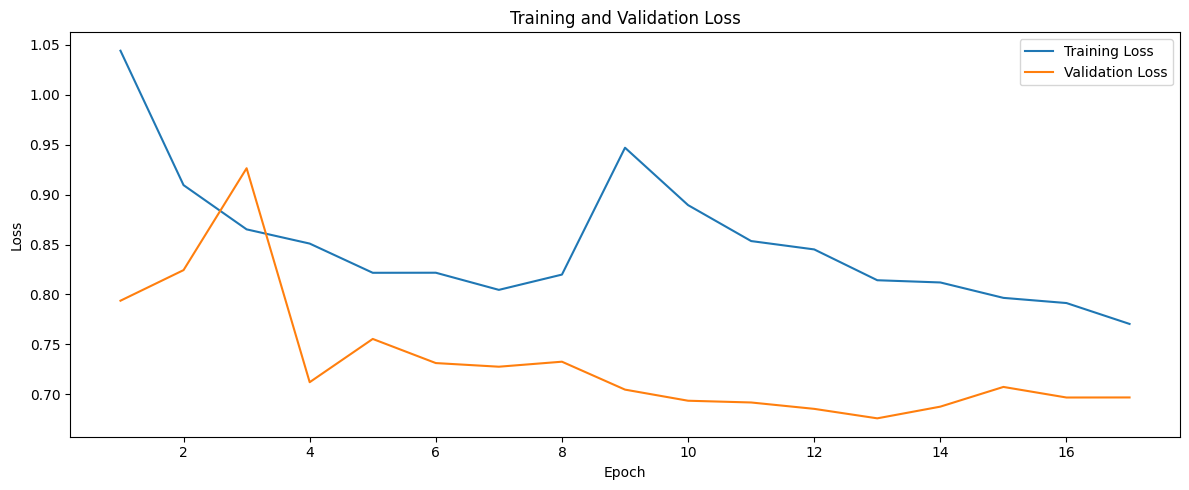

In [ ]:
# ============================================================
# 22. TRAINING CURVES
# ============================================================

def combine_history(history1, history2):
    """
    Combine the histories from initial training
    and fine-tuning.
    """

    history = {}

    for key in history1.history.keys():

        history[key] = (
            history1.history[key] +
            history2.history[key]
        )

    return history


combined_history = combine_history(
    history_head,
    history_finetune
)


epochs = range(
    1,
    len(combined_history["accuracy"]) + 1
)

plt.figure(figsize=(12, 5))

plt.plot(
    epochs,
    combined_history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    combined_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    epochs,
    combined_history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    combined_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 23. MODEL EVALUATION
# ============================================================

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 17s 747ms/step - accuracy: 0.6951 - loss: 0.7159

Test Loss: 0.7159
Test Accuracy: 0.6951


In [ ]:
# ============================================================
# 24. TEST SET PREDICTIONS
# ============================================================

y_true = []
y_pred = []
y_probabilities = []


for images, labels in test_ds:

    probabilities = model.predict(
        images,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predictions
    )

    y_probabilities.extend(
        probabilities
    )


y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probabilities = np.array(y_probabilities)

print("Predictions generated:", len(y_pred))

Predictions generated: 692


In [ ]:
# ============================================================
# 25. CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(CLASS_NAMES.values()),
        digits=4
    )
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro"
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro"
)

print(f"Accuracy        : {accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")

              precision    recall  f1-score   support

     Pothole     0.5808    0.5449    0.5623       178
       Crack     0.7915    0.8311    0.8108       379
     Manhole     0.5433    0.5111    0.5267       135

    accuracy                         0.6951       692
   macro avg     0.6385    0.6291    0.6333       692
weighted avg     0.6889    0.6951    0.6915       692

Accuracy        : 0.6951
Macro Precision : 0.6385
Macro Recall    : 0.6291
Macro F1        : 0.6333


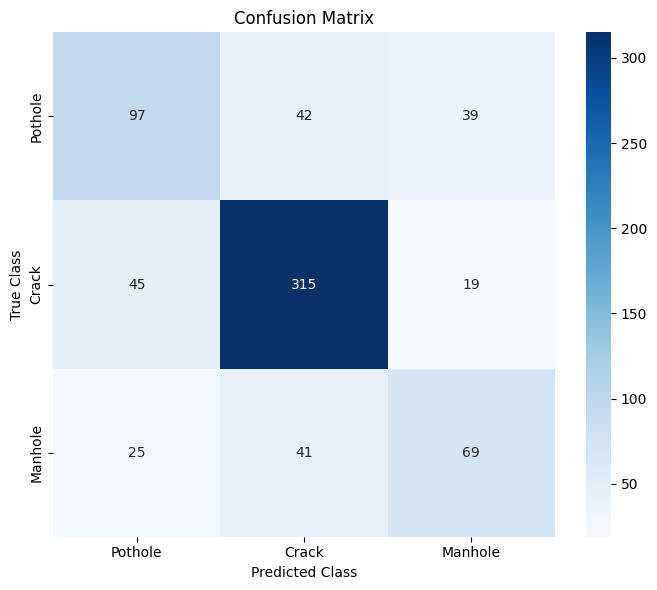

In [ ]:
# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES.values(),
    yticklabels=CLASS_NAMES.values()
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

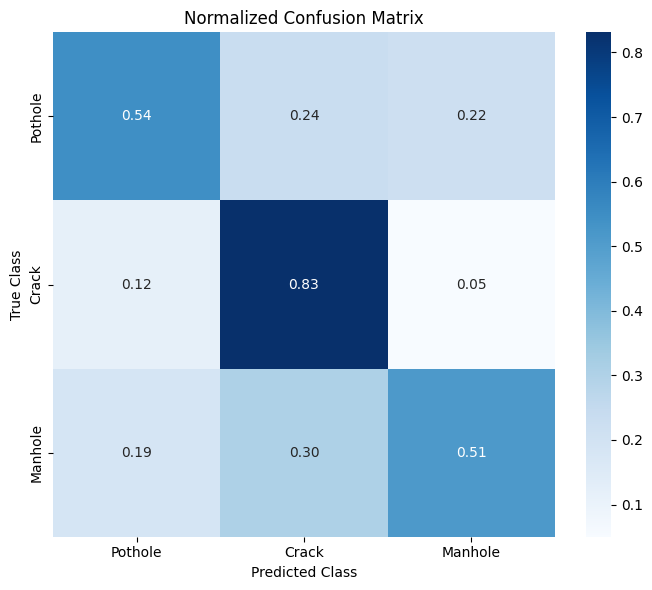

In [ ]:
# ============================================================
# 27. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = (
    cm.astype(float)
    / cm.sum(axis=1, keepdims=True)
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASS_NAMES.values(),
    yticklabels=CLASS_NAMES.values()
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 28. FIND A GRAD-CAM LAYER
# ============================================================

# Look for the final convolutional layer inside MobileNetV2

for layer in reversed(base_model.layers):

    if isinstance(layer, layers.Conv2D):
        print("Grad-CAM layer:", layer.name)
        LAST_CONV_LAYER = layer.name
        break

Grad-CAM layer: Conv_1


In [ ]:
# ============================================================
# 29. GRAD-CAM FUNCTION
# ============================================================

def make_gradcam_heatmap(
    image_array,
    model,
    base_model,
    last_conv_layer_name,
    pred_index=None
):
    """
    Generate Grad-CAM for the trained MobileNetV2 classifier.

    This implementation avoids creating a new Functional graph
    through the nested MobileNetV2 model.

    Instead:
        Image
          ↓
        MobileNetV2
          ├── intermediate Conv layer → Grad-CAM
          └── final feature map
                    ↓
              Global Average Pooling
                    ↓
                Dense head
                    ↓
                 Softmax
    """

    # --------------------------------------------------------
    # Get the target convolutional layer
    # --------------------------------------------------------

    last_conv_layer = base_model.get_layer(
        last_conv_layer_name
    )

    # --------------------------------------------------------
    # Get your trained classification layer
    # --------------------------------------------------------

    prediction_layer = model.get_layer(
        "predictions"
    )

    # --------------------------------------------------------
    # Create a model that ONLY belongs to MobileNetV2
    #
    # This is the important change that avoids the Keras
    # nested-model tensor graph problem.
    # --------------------------------------------------------

    conv_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    # --------------------------------------------------------
    # Forward pass
    # --------------------------------------------------------

    with tf.GradientTape() as tape:

        conv_outputs, backbone_output = conv_model(
            image_array,
            training=False
        )

        # Global Average Pooling
        pooled_output = tf.reduce_mean(
            backbone_output,
            axis=[1, 2]
        )

        # Apply the already-trained Dense classification layer
        logits = prediction_layer(
            pooled_output
        )

        predictions = logits

        # ----------------------------------------------------
        # Select target class
        # ----------------------------------------------------

        if pred_index is None:
            pred_index = tf.argmax(
                predictions[0]
            )

        class_score = predictions[:, pred_index]

    # --------------------------------------------------------
    # Gradient of selected class with respect to
    # convolutional feature maps
    # --------------------------------------------------------

    grads = tape.gradient(
        class_score,
        conv_outputs
    )

    # --------------------------------------------------------
    # Average gradients across height and width
    # --------------------------------------------------------

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # --------------------------------------------------------
    # Weighted combination of feature maps
    # --------------------------------------------------------

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # --------------------------------------------------------
    # ReLU
    #
    # We only keep positive influence on the selected class.
    # --------------------------------------------------------

    heatmap = tf.maximum(
        heatmap,
        0
    )

    # --------------------------------------------------------
    # Normalize heatmap to [0, 1]
    # --------------------------------------------------------

    max_heatmap = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_heatmap > 0,
        heatmap / max_heatmap,
        heatmap
    )

    return heatmap.numpy()

In [ ]:
# ============================================================
# 30. GRAD-CAM SETUP
# ============================================================

# Find MobileNetV2 automatically
base_model = None

for layer in model.layers:

    if isinstance(layer, tf.keras.Model):

        if "mobilenet" in layer.name.lower():

            base_model = layer

            break


if base_model is None:

    raise ValueError(
        "Could not find the MobileNetV2 backbone."
    )


print(
    "Backbone:",
    base_model.name
)


# ------------------------------------------------------------
# 31. Find final Conv2D layer
# ------------------------------------------------------------

LAST_CONV_LAYER = None

for layer in reversed(base_model.layers):

    if isinstance(
        layer,
        tf.keras.layers.Conv2D
    ):

        LAST_CONV_LAYER = layer.name

        break


if LAST_CONV_LAYER is None:

    raise ValueError(
        "Could not find a Conv2D layer for Grad-CAM."
    )


print(
    "Grad-CAM target layer:",
    LAST_CONV_LAYER
)

Backbone: mobilenetv2_1.00_224
Grad-CAM target layer: Conv_1


In [ ]:
# ============================================================
# 32. GRAD-CAM DIAGNOSTIC TEST
# ============================================================

sample = test_df.sample(
    1,
    random_state=SEED
).iloc[0]

image_path = sample["crop_path"]

print("Testing image:")
print(image_path)


# Load image
img = cv2.imread(
    image_path
)

if img is None:

    raise ValueError(
        "Could not load test image."
    )


img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)


# Resize
img_resized = cv2.resize(
    img,
    IMG_SIZE
)


# Preprocess
input_tensor = preprocess_input(
    img_resized.astype(
        np.float32
    )
)

input_tensor = np.expand_dims(
    input_tensor,
    axis=0
)


print(
    "Input shape:",
    input_tensor.shape
)


# Test Grad-CAM
heatmap = make_gradcam_heatmap(
    input_tensor,
    model,
    base_model,
    LAST_CONV_LAYER
)


print(
    "Heatmap generated successfully!"
)

print(
    "Heatmap shape:",
    heatmap.shape
)

print(
    "Heatmap min:",
    heatmap.min()
)

print(
    "Heatmap max:",
    heatmap.max()
)

Testing image:
/kaggle/working/road_damage_crops/Crack/vlcsnap-2025-02-18-18h47m06s542_obj_2570.jpg
Input shape: (1, 224, 224, 3)
Heatmap generated successfully!
Heatmap shape: (7, 7)
Heatmap min: 0.0
Heatmap max: 1.0


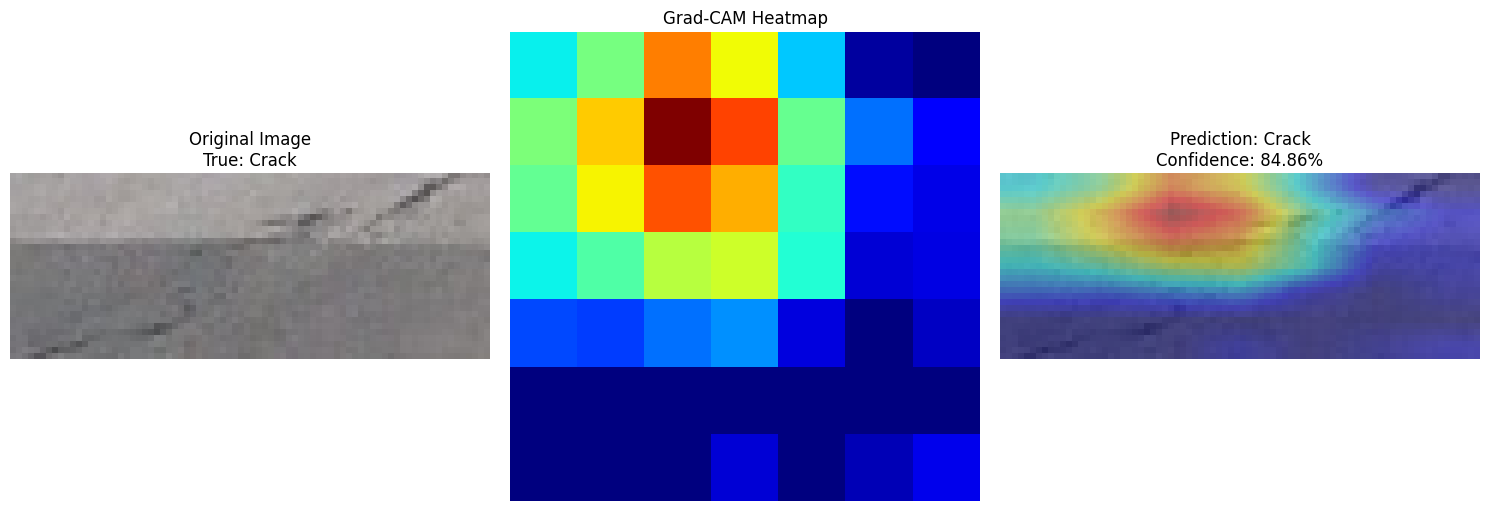

In [ ]:
# ============================================================
# 33. GRAD-CAM EXAMPLE
# ============================================================

# Select a random test sample
sample = test_df.sample(
    1,
    random_state=SEED
).iloc[0]

image_path = sample["crop_path"]
true_class = sample["class_name"]


# ------------------------------------------------------------
# Load image
# ------------------------------------------------------------

img = cv2.imread(
    image_path
)

if img is None:

    raise ValueError(
        f"Could not load image: {image_path}"
    )


img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)


# ------------------------------------------------------------
# Prepare model input
# ------------------------------------------------------------

img_resized = cv2.resize(
    img,
    IMG_SIZE
)

input_tensor = preprocess_input(
    img_resized.astype(
        np.float32
    )
)

input_tensor = np.expand_dims(
    input_tensor,
    axis=0
)


# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

predictions = model.predict(
    input_tensor,
    verbose=0
)[0]


predicted_index = np.argmax(
    predictions
)


predicted_class = index_to_class[
    predicted_index
]


confidence = predictions[
    predicted_index
]


# ------------------------------------------------------------
# Grad-CAM
# ------------------------------------------------------------

heatmap = make_gradcam_heatmap(
    input_tensor,
    model,
    base_model,
    LAST_CONV_LAYER,
    pred_index=predicted_index
)


# ------------------------------------------------------------
# Overlay
# ------------------------------------------------------------

original, overlay = overlay_gradcam(
    image_path,
    heatmap
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

plt.figure(
    figsize=(15, 5)
)


# Original
plt.subplot(
    1, 3, 1
)

plt.imshow(
    original
)

plt.title(
    f"Original Image\n"
    f"True: {true_class}"
)

plt.axis("off")


# Heatmap
plt.subplot(
    1, 3, 2
)

plt.imshow(
    heatmap,
    cmap="jet"
)

plt.title(
    "Grad-CAM Heatmap"
)

plt.axis("off")


# Overlay
plt.subplot(
    1, 3, 3
)

plt.imshow(
    overlay
)

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)

plt.axis("off")


plt.tight_layout()

plt.show()

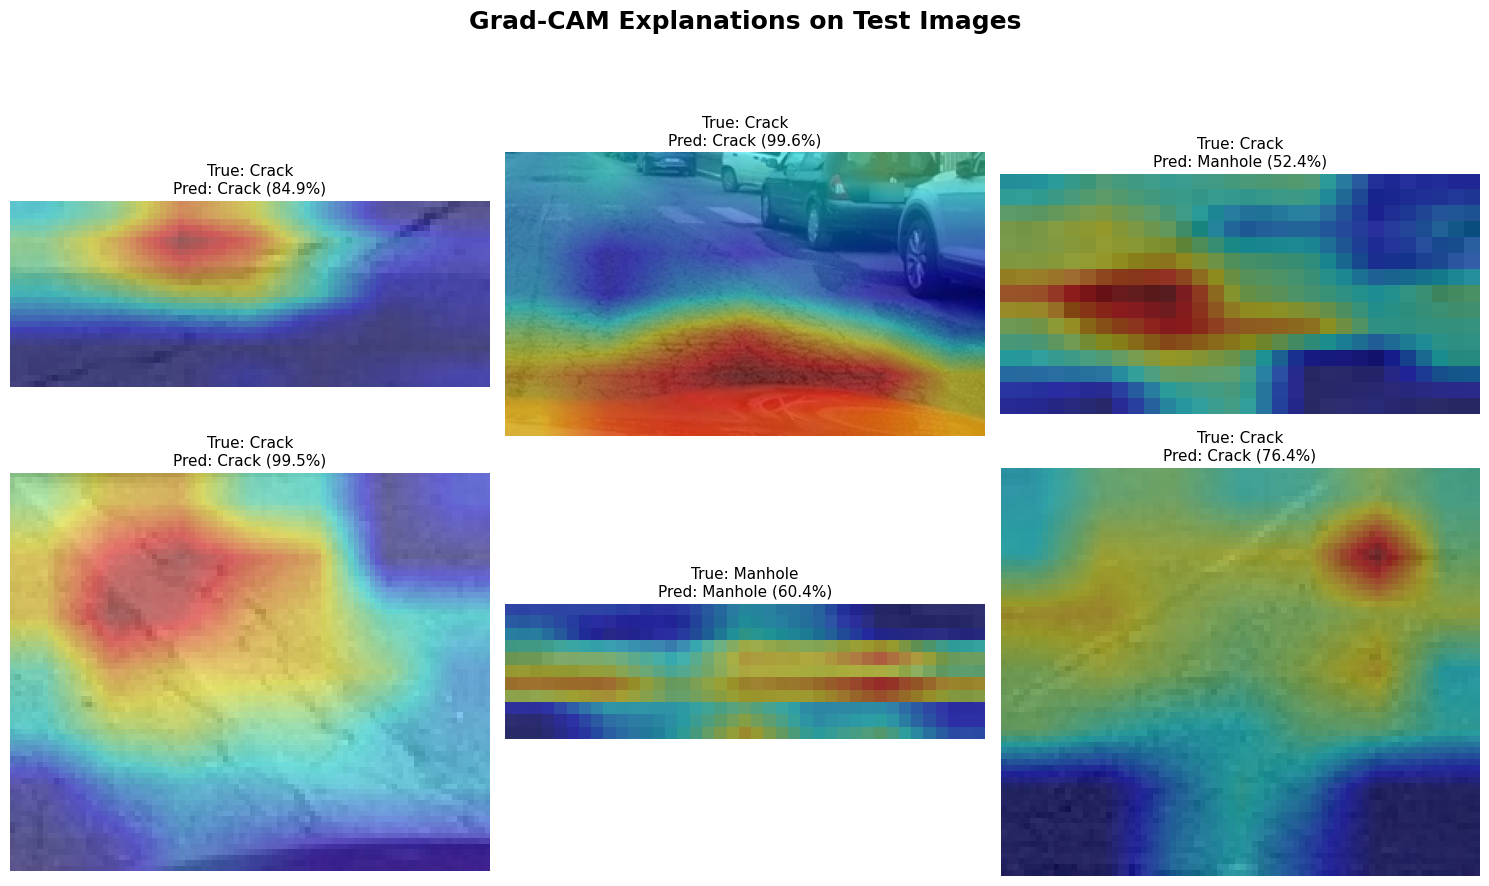

In [ ]:
# ============================================================
# 34. MULTIPLE GRAD-CAM EXAMPLES
# ============================================================

# Select up to 6 random test samples
samples = test_df.sample(
    min(6, len(test_df)),
    random_state=SEED
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.flatten()


for ax, (_, row) in zip(
    axes,
    samples.iterrows()
):

    image_path = row["crop_path"]
    true_class = row["class_name"]


    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    img = cv2.imread(
        image_path
    )

    if img is None:
        ax.axis("off")
        ax.set_title("Image could not be loaded")
        continue

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )


    # --------------------------------------------------------
    # Resize for MobileNetV2
    # --------------------------------------------------------

    resized = cv2.resize(
        img,
        IMG_SIZE
    )


    # --------------------------------------------------------
    # Preprocess
    # --------------------------------------------------------

    input_tensor = preprocess_input(
        resized.astype(
            np.float32
        )
    )

    input_tensor = np.expand_dims(
        input_tensor,
        axis=0
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    probabilities = model.predict(
        input_tensor,
        verbose=0
    )[0]

    pred_index = np.argmax(
        probabilities
    )

    pred_class = index_to_class[
        pred_index
    ]

    confidence = probabilities[
        pred_index
    ]


    # --------------------------------------------------------
    # Generate Grad-CAM
    # --------------------------------------------------------

    heatmap = make_gradcam_heatmap(
        input_tensor,
        model,
        base_model,
        LAST_CONV_LAYER,
        pred_index=pred_index
    )


    # --------------------------------------------------------
    # Create overlay
    # --------------------------------------------------------

    _, overlay = overlay_gradcam(
        image_path,
        heatmap
    )


    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    ax.imshow(
        overlay
    )

    ax.set_title(
        f"True: {true_class}\n"
        f"Pred: {pred_class} "
        f"({confidence:.1%})",
        fontsize=11
    )

    ax.axis("off")


# ------------------------------------------------------------
# Overall figure title
# ------------------------------------------------------------

plt.suptitle(
    "Grad-CAM Explanations on Test Images",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

In [ ]:
# ============================================================
# 35. CORRECT VS INCORRECT PREDICTIONS
# ============================================================

test_results = test_df.reset_index(drop=True).copy()

test_results["true_label"] = (
    test_results["label"]
)

test_results["pred_label"] = y_pred

test_results["pred_class"] = [
    index_to_class[i]
    for i in y_pred
]

test_results["confidence"] = (
    np.max(
        y_probabilities,
        axis=1
    )
)

test_results["correct"] = (
    test_results["true_label"]
    ==
    test_results["pred_label"]
)

print(
    "Correct predictions:",
    test_results["correct"].sum()
)

print(
    "Incorrect predictions:",
    (~test_results["correct"]).sum()
)

Correct predictions: 481
Incorrect predictions: 211


Number of misclassified samples: 211


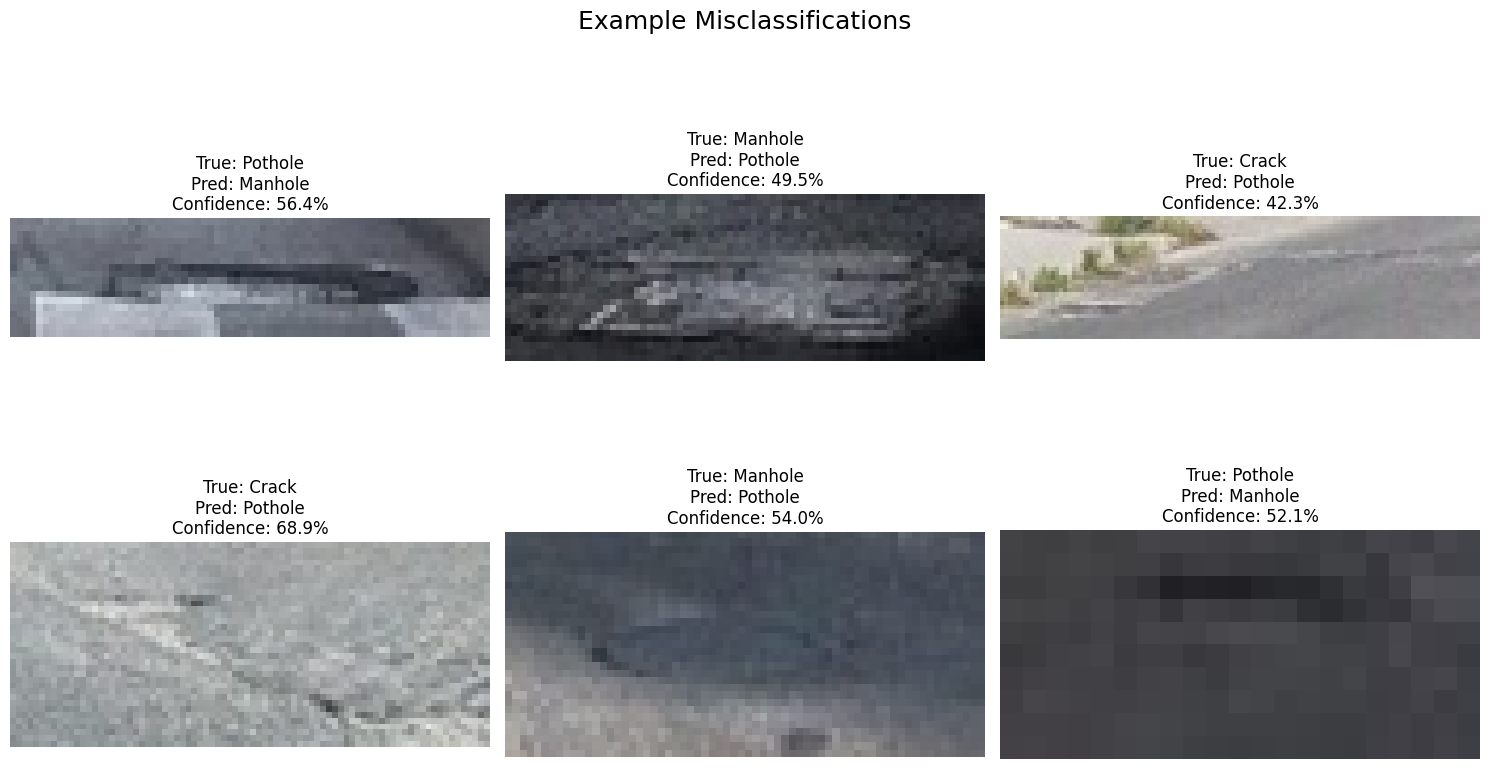

In [ ]:
# ============================================================
# 36. MISCLASSIFIED EXAMPLES
# ============================================================

errors = test_results[
    ~test_results["correct"]
]

print(
    f"Number of misclassified samples: {len(errors)}"
)

if len(errors) > 0:

    samples = errors.sample(
        min(6, len(errors)),
        random_state=SEED
    )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 9)
    )

    axes = axes.flatten()

    for ax, (_, row) in zip(
        axes,
        samples.iterrows()
    ):

        image = cv2.imread(
            row["crop_path"]
        )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(image)

        ax.set_title(
            f"True: {row['class_name']}\n"
            f"Pred: {row['pred_class']}\n"
            f"Confidence: {row['confidence']:.1%}"
        )

        ax.axis("off")

    plt.suptitle(
        "Example Misclassifications",
        fontsize=18
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 37. SAVE MODEL
# ============================================================

MODEL_PATH = "/kaggle/working/road_damage_mobilenetv2.keras"

model.save(
    MODEL_PATH
)

print(
    "Model saved to:",
    MODEL_PATH
)

Model saved to: /kaggle/working/road_damage_mobilenetv2.keras


In [ ]:
# ============================================================
# 38. SINGLE IMAGE PREDICTION FUNCTION
# ============================================================

def predict_road_damage(
    image_path,
    model,
    base_model,
    last_conv_layer_name
):

    # -------------------------
    # Load image
    # -------------------------

    image = cv2.imread(
        image_path
    )

    if image is None:
        raise ValueError(
            f"Could not read image: {image_path}"
        )

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # -------------------------
    # Prepare model input
    # -------------------------

    resized = cv2.resize(
        image_rgb,
        IMG_SIZE
    )

    input_tensor = preprocess_input(
        resized.astype(np.float32)
    )

    input_tensor = np.expand_dims(
        input_tensor,
        axis=0
    )

    # -------------------------
    # Prediction
    # -------------------------

    probabilities = model.predict(
        input_tensor,
        verbose=0
    )[0]

    pred_index = np.argmax(
        probabilities
    )

    pred_class = index_to_class[
        pred_index
    ]

    confidence = probabilities[
        pred_index
    ]

    # -------------------------
    # Grad-CAM
    # -------------------------

    heatmap = make_gradcam_heatmap(
        input_tensor,
        model,
        base_model,
        last_conv_layer_name,
        pred_index=pred_index
    )

    _, overlay = overlay_gradcam(
        image_path,
        heatmap
    )

    return {
        "prediction": pred_class,
        "confidence": confidence,
        "probabilities": probabilities,
        "heatmap": heatmap,
        "overlay": overlay,
        "original": image_rgb
    }

Prediction: Manhole
Confidence: 67.04%


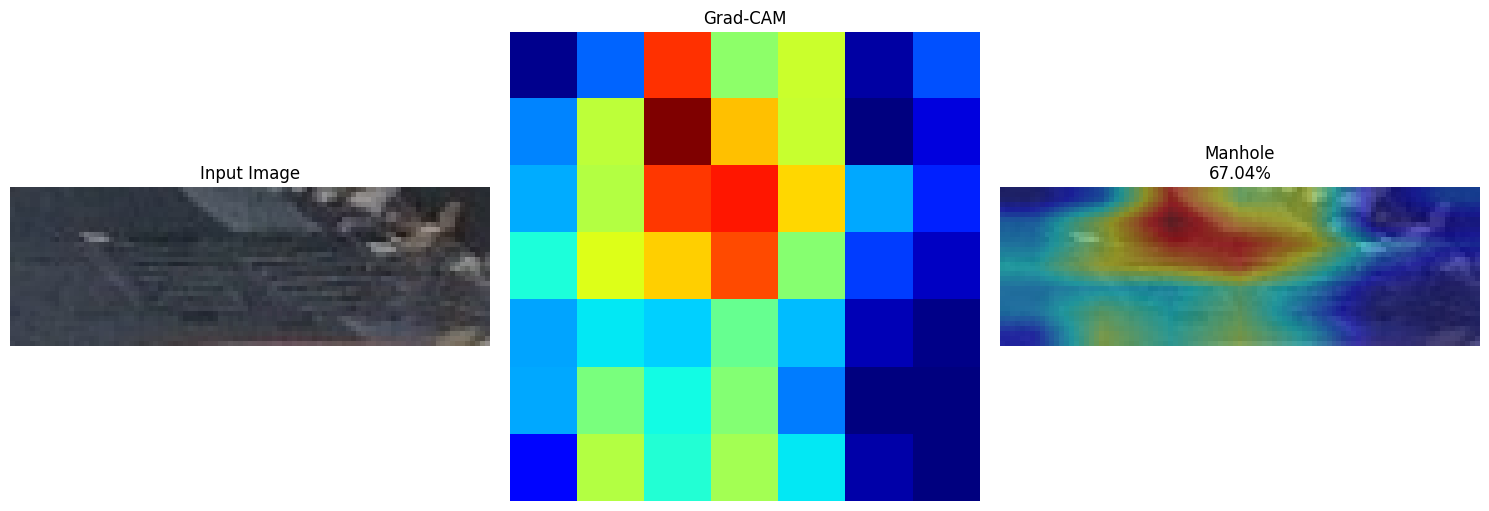

In [ ]:
# ============================================================
# 39. DEMO
# ============================================================

demo_path = test_df.sample(
    1,
    random_state=100
).iloc[0]["crop_path"]

result = predict_road_damage(
    demo_path,
    model,
    base_model,
    LAST_CONV_LAYER
)

print(
    f"Prediction: {result['prediction']}"
)

print(
    f"Confidence: {result['confidence']:.2%}"
)


plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    result["original"]
)

plt.title("Input Image")
plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    result["heatmap"],
    cmap="jet"
)

plt.title("Grad-CAM")
plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    result["overlay"]
)

plt.title(
    f"{result['prediction']}\n"
    f"{result['confidence']:.2%}"
)

plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 40. FINAL METRICS TABLE
# ============================================================

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Score": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

metrics_df["Score"] = (
    metrics_df["Score"]
    .round(4)
)

metrics_df

,Metric,Score
0,Accuracy,0.6951
1,Macro Precision,0.6385
2,Macro Recall,0.6291
3,Macro F1,0.6333


In [ ]:
# ============================================================
# 41. SAVE METRICS
# ============================================================

metrics_df.to_csv(
    "/kaggle/working/road_damage_metrics.csv",
    index=False
)

test_results.to_csv(
    "/kaggle/working/test_predictions.csv",
    index=False
)

print("Metrics and predictions saved.")

Metrics and predictions saved.


In [ ]:
# ============================================================
# 42. MODEL SIZE
# ============================================================

total_params = model.count_params()

trainable_params = (
    np.sum([
        np.prod(v.shape)
        for v in model.trainable_variables
    ])
)

print(
    f"Total parameters: {total_params:,}"
)

print(
    f"Trainable parameters: {trainable_params:,}"
)

Total parameters: 2,261,827
Trainable parameters: 1,865,283


# Final Project Summary

## Problem

Automatically classify road-surface damage from images while
providing a visual explanation for each prediction.

## Dataset

Road Damage Dataset: Potholes, Cracks and Manholes.

Classes:
- Pothole
- Crack
- Manhole

## Methodology

1. Parse YOLO polygon annotations.
2. Convert annotations into individual damage crops.
3. Split data at the original-image level.
4. Apply image resizing and augmentation.
5. Use MobileNetV2 with ImageNet pretrained weights.
6. Train a three-class classification head.
7. Fine-tune upper layers of the CNN.
8. Evaluate using accuracy, precision, recall and macro-F1.
9. Generate a confusion matrix.
10. Use Grad-CAM to explain predictions.

## Final Output

Input Image
    ↓
MobileNetV2
    ↓
Predicted Damage Class
    +
Confidence Score
    +
Grad-CAM Heatmap

The model therefore provides both:
"What is the damage?"
and
"Where did the model focus when making the prediction?"